In [1]:
import numpy as np, pandas as pd, torch, torch.nn as nn
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.preprocessing import StandardScaler
sns.set_theme(style="whitegrid")

c = pd.read_csv("../data/processed/manali_model.csv", index_col="Date", parse_dates=True)
EXOG = ["PM2.5", "NO2", "SO2", "NH3"]          # CO is excluded (stuck sensor); NO and NOx duplicate NO2
n = len(c); i1, i2 = int(n * 0.70), int(n * 0.85)   # same split as the ARIMA notebook
L = 14                                              # window length: days of history the model sees
y_raw = c["AQI"].values.astype(float)

def metrics(actual, pred):
    a, p = np.asarray(actual, float), np.asarray(pred, float)
    return {"MAE": np.mean(np.abs(a - p)), "RMSE": np.sqrt(np.mean((a - p) ** 2)),
            "sMAPE %": 100 * np.mean(2 * np.abs(a - p) / (np.abs(a) + np.abs(p)))}

def build(cols):
    F = c[cols].values.astype(float)
    sc = StandardScaler().fit(F[:i1])                 # statistics from training days only
    Z = sc.transform(F)
    mu, sd = sc.mean_[0], sc.scale_[0]                # AQI is column 0
    T = np.arange(L, n)                               # target day t uses days t-L ... t-1
    X = np.stack([Z[t - L:t] for t in T])
    Y = np.array([Z[t, 0] for t in T])
    masks = {"train": T < i1, "val": (T >= i1) & (T < i2), "test": T >= i2}
    return (torch.tensor(X, dtype=torch.float32), torch.tensor(Y, dtype=torch.float32), masks, mu, sd)

X, Y, masks, mu, sd = build(["AQI"])
print("windows:", X.shape, "| train/val/test targets:", {k: int(m.sum()) for k, m in masks.items()})

windows: torch.Size([570, 14, 1]) | train/val/test targets: {'train': 394, 'val': 88, 'test': 88}


In [2]:
class LSTMForecaster(nn.Module):
    def __init__(self, n_features, hidden=32):
        super().__init__()
        self.lstm = nn.LSTM(n_features, hidden, batch_first=True)
        self.head = nn.Linear(hidden, 1)
    def forward(self, x):
        out, _ = self.lstm(x)                  # out: (batch, days, hidden)
        return self.head(out[:, -1, :]).squeeze(-1)   # use the last day's memory to predict

def train_model(Xtr, ytr, Xva, yva, n_features, seed=0, lr=1e-3, epochs=300, patience=25):
    torch.manual_seed(seed)
    model = LSTMForecaster(n_features)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    loss_fn = nn.MSELoss()
    best, best_state, wait, hist = np.inf, None, 0, []
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(Xtr))
        for i in range(0, len(Xtr), 32):
            b = perm[i:i + 32]
            opt.zero_grad()
            loss_fn(model(Xtr[b]), ytr[b]).backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            tl, vl = loss_fn(model(Xtr), ytr).item(), loss_fn(model(Xva), yva).item()
        hist.append((tl, vl))
        if vl < best - 1e-5:
            best, wait = vl, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= patience:
                break
    model.load_state_dict(best_state)           # keep the weights from the best validation epoch
    return model, hist

In [4]:
def run_variant(cols, seeds=range(5)):
    X, Y, masks, mu, sd = build(cols)
    tr, va, te = [torch.from_numpy(masks[k]) for k in ("train", "val", "test")]
    pv, pt, hist = [], [], None
    for s in seeds:
        model, hist = train_model(X[tr], Y[tr], X[va], Y[va], X.shape[2], seed=s)
        with torch.no_grad():
            pv.append(model(X[va]).numpy() * sd + mu)       # back to real AQI units
            pt.append(model(X[te]).numpy() * sd + mu)
    return np.array(pv), np.array(pt), hist

results, hists = {}, {}
for name, cols in {"LSTM (AQI only)": ["AQI"], "LSTM (AQI + pollutants)": ["AQI"] + EXOG}.items():
    results[name] = run_variant(cols)[:2]
    print("done:", name)

done: LSTM (AQI only)
done: LSTM (AQI + pollutants)


In [5]:
act_val, act_test = y_raw[i1:i2], y_raw[i2:]
arima = pd.read_csv("../data/processed/preds_test_arima.csv", index_col=0, parse_dates=True)

rows = {"persistence": metrics(act_test, arima["persistence"]),
        "ARIMA(2,0,0)": metrics(act_test, arima["arima"])}
for name, (pv, pt) in results.items():
    rows[name + " (average of 5 runs)"] = metrics(act_test, pt.mean(axis=0))
tab = pd.DataFrame(rows).T
tab["skill vs persistence"] = 1 - tab["MAE"] / tab.loc["persistence", "MAE"]
display(tab.round(2))

print("\nRun-to-run spread of the test MAE (mean and std over 5 seeds):")
for name, (pv, pt) in results.items():
    m = [metrics(act_test, p)["MAE"] for p in pt]
    print(f"  {name}: {np.mean(m):.2f} +/- {np.std(m):.2f}")
print("\nValidation MAE (used for early stopping):")
for name, (pv, pt) in results.items():
    print(f"  {name}: {metrics(act_val, pv.mean(axis=0))['MAE']:.2f}")

,MAE,RMSE,sMAPE %,skill vs persistence
persistence,24.38,40.79,17.80,0.00
"ARIMA(2,0,0)",25.71,36.99,20.08,-0.05
LSTM (AQI only) (average of 5 runs),23.33,35.09,17.98,0.04
LSTM (AQI + pollutants) (average of 5 runs),26.35,35.45,23.00,-0.08



Run-to-run spread of the test MAE (mean and std over 5 seeds):
  LSTM (AQI only): 23.51 +/- 0.64
  LSTM (AQI + pollutants): 26.65 +/- 1.20

Validation MAE (used for early stopping):
  LSTM (AQI only): 47.82
  LSTM (AQI + pollutants): 41.34


Alerts (AQI > 200):
persistence: {'event days': 5, 'caught': 2, 'missed': 3, 'false alarms': 3}
ARIMA:       {'event days': 5, 'caught': 2, 'missed': 3, 'false alarms': 2}
LSTM (AQI only): {'event days': 5, 'caught': 2, 'missed': 3, 'false alarms': 2}
LSTM (AQI + pollutants): {'event days': 5, 'caught': 2, 'missed': 3, 'false alarms': 0}


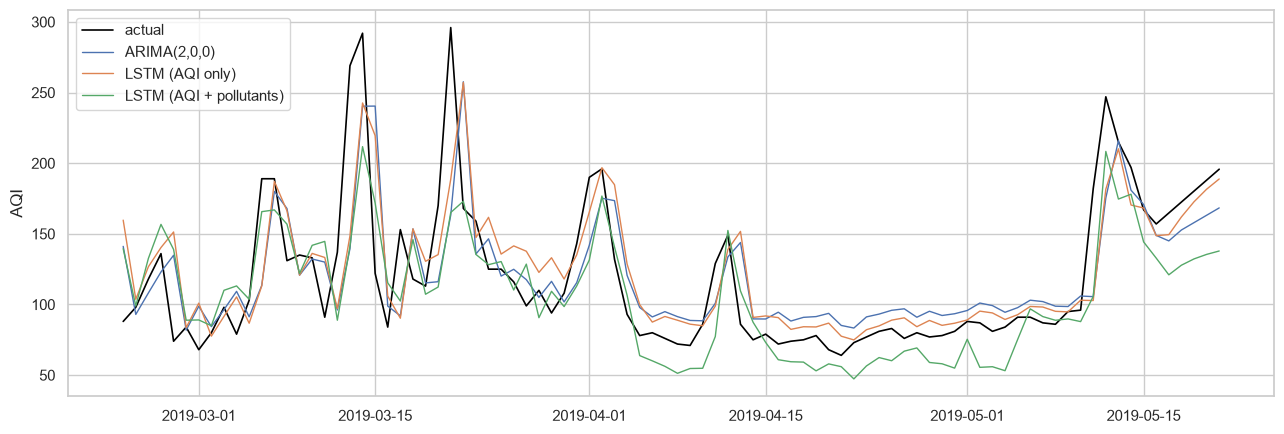

Saved (88, 5)


In [6]:
def alerts(actual, pred, thr=200):
    a, p = np.asarray(actual) > thr, np.asarray(pred) > thr
    return {"event days": int(a.sum()), "caught": int((a & p).sum()),
            "missed": int((a & ~p).sum()), "false alarms": int((~a & p).sum())}

print("Alerts (AQI > 200):")
print("persistence:", alerts(act_test, arima["persistence"]))
print("ARIMA:      ", alerts(act_test, arima["arima"]))
for name, (pv, pt) in results.items():
    print(f"{name}:", alerts(act_test, pt.mean(axis=0)))

dates = c.index[i2:]
plt.figure(figsize=(13, 4.5))
plt.plot(dates, act_test, label="actual", lw=1.2, color="black")
plt.plot(dates, arima["arima"], label="ARIMA(2,0,0)", lw=1)
for name, (pv, pt) in results.items():
    plt.plot(dates, pt.mean(axis=0), label=name, lw=1)
plt.legend(); plt.ylabel("AQI")
plt.tight_layout(); plt.savefig("../figures/05_forecast_comparison.png", dpi=150); plt.show()

out = pd.DataFrame({"actual": act_test, "persistence": arima["persistence"].values, "arima": arima["arima"].values,
                    "lstm_aqi_only": results["LSTM (AQI only)"][1].mean(axis=0),
                    "lstm_with_pollutants": results["LSTM (AQI + pollutants)"][1].mean(axis=0)}, index=dates)
out.to_csv("../data/processed/preds_test_all.csv")
print("Saved", out.shape)

In [7]:
rng = np.random.default_rng(0)

def block_bootstrap_diff(err_a, err_b, block=7, n_boot=5000):
    d = np.asarray(err_a) - np.asarray(err_b)          # positive = model A has the larger error
    n_days = len(d); n_blocks = int(np.ceil(n_days / block))
    means = []
    for _ in range(n_boot):
        starts = rng.integers(0, n_days - block + 1, n_blocks)
        means.append(np.concatenate([d[s:s + block] for s in starts])[:n_days].mean())
    lo, hi = np.percentile(means, [2.5, 97.5])
    return d.mean(), lo, hi

pers_err = np.abs(act_test - arima["persistence"].values)
cands = {"ARIMA": np.abs(act_test - arima["arima"].values),
         "LSTM (AQI only)": np.abs(act_test - results["LSTM (AQI only)"][1].mean(axis=0)),
         "LSTM (AQI + pollutants)": np.abs(act_test - results["LSTM (AQI + pollutants)"][1].mean(axis=0))}
for name, e in cands.items():
    m, lo, hi = block_bootstrap_diff(e, pers_err)
    print(f"{name} minus persistence (MAE): {m:+.2f}  (95% interval {lo:+.2f} to {hi:+.2f})")

ARIMA minus persistence (MAE): +1.33  (95% interval -2.59 to +4.67)
LSTM (AQI only) minus persistence (MAE): -1.06  (95% interval -4.48 to +1.99)
LSTM (AQI + pollutants) minus persistence (MAE): +1.97  (95% interval -5.59 to +7.14)


In [8]:
sens = {}
for L_try in (7, 14, 21):
    L = L_try                                   # build() reads this global variable
    pv, pt, _ = run_variant(["AQI"])
    sens[L_try] = {"val MAE": metrics(act_val, pv.mean(axis=0))["MAE"],
                   "test MAE": metrics(act_test, pt.mean(axis=0))["MAE"]}
L = 14
pd.DataFrame(sens).T.round(2)

,val MAE,test MAE
7,48.59,23.48
14,47.82,23.33
21,48.72,25.31
